# One store, two atlases — virtualize, then it's just AnnData

We take two independently published [CZ CELLxGENE](https://cellxgene.cziscience.com/)
studies and reference them into a **single [Icechunk](https://icechunk.io)
repository** — copying none of the expression matrices:

- **Allen Institute Human Immune Health Atlas** — distributed as one `.h5ad` per
  cell type, sharing a 32,357-gene panel (we use two files here).
- **Ocular surface atlas** — a single ~10 GB `.h5ad`, 815,769 cells.

The two studies have different genes and different cell metadata, so they can't be
one matrix — they live as two **groups**, `/allen` and `/ocular`, in the same repo.

**The point:** once virtualized, there is no special API to learn. You
`open_anndata(...)` and everything after is ordinary `AnnData` + `scanpy` — slice
by metadata, read only the cells you touch, plot embeddings. At the end we compute
a value *over* the virtual matrix and write it **back into the repo as native
chunks**, so the next reader just sees it as another column.

## Build the store (the publisher's one-time step)

One `virtualize_matrix` call per study. `X` (and, for a single-file study, the
dense `obsm` embeddings) become byte-range references into the original files;
`obs`/`var` are copied in so the repo is self-contained. `overwrite=False` on the
second call **appends** its group to the same repo.

In [1]:
import os, time, glob
from virtual_h5ad import virtualize_matrix

REPO = "repo/atlas"
OCULAR = "data/ocular_cache/30127f02-d0b9-4b56-bf4c-e5b77e4989bd.h5ad"

virtualize_matrix("data/allen", REPO, group="allen")                 # 2 files, shared genes
virtualize_matrix(OCULAR, REPO, group="ocular", overwrite=False)    # 1 file, ~10 GB
print("built repo/atlas with groups: allen, ocular")

built repo/atlas with groups: allen, ocular


In [2]:
def dir_bytes(p):
    return sum(os.path.getsize(os.path.join(r, f))
               for r, _, fs in os.walk(p) for f in fs)

src = sum(os.path.getsize(f) for f in glob.glob("data/allen/*.h5ad")) + os.path.getsize(OCULAR)
repo = dir_bytes(REPO)
print(f"source files : {src/1e9:6.2f} GB")
print(f"repository   : {repo/1e6:6.1f} MB   ({src/repo:.0f}x smaller)")
print("the matrices were never copied — the repo is references + metadata")

source files :  10.70 GB
repository   :   50.1 MB   (213x smaller)
the matrices were never copied — the repo is references + metadata


## From here, it's just AnnData

`open_anndata` returns an ordinary `AnnData`. Opening reads **no** expression
data — `X` is backed (read on slice), and `obs`/`var` came from the repo. Each
group is opened by name.

In [3]:
from virtual_h5ad import open_anndata

t = time.time()
allen  = open_anndata(REPO, group="allen")
ocular = open_anndata(REPO, group="ocular")
print(f"opened both groups in {time.time()-t:.2f}s (no expression data read)\n")
print("allen :", allen.shape,  "| obsm:", list(allen.obsm))
print("ocular:", ocular.shape, "| obsm:", list(ocular.obsm))
ocular

opened both groups in 0.52s (no expression data read)

allen : (34224, 32357) | obsm: ['X_pca_harmony', 'X_pca', 'X_umap']
ocular: (815769, 35477) | obsm: ['X_scVI', 'X_umap']


AnnData object with n_obs × n_vars = 815769 × 35477
    obs: 'reference_genome', 'gene_annotation_version', 'alignment_software', 'intronic_reads_counted', 'donor_id', 'donor_age', 'self_reported_ethnicity_ontology_term_id', 'donor_living_at_sample_collection', 'sample_id', 'sample_preservation_method', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'sample_collection_method', 'tissue_source', 'tissue_type', 'suspension_derivation_process', 'suspension_dissociation_reagent', 'suspension_dissociation_time', 'suspension_uuid', 'suspension_type', 'library_id', 'assay_ontology_term_id', 'sequenced_fragment', 'institute', 'library_id_repository', 'is_primary_data', 'cell_type_ontology_term_id', 'author_cell_type', 'disease_ontology_term_id', 'sex_ontology_term_id', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'pANN', 'study', 'sampleid', 'published_annotation', 'majorclass', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'o

### Metadata exploration is free

Every per-cell field lives in the repo, so summarizing 850k cells touches none of
the matrices.

In [4]:
print("Allen — cell types:")
print(allen.obs["cell_type"].value_counts().head(5))
print("\nOcular — tissues:")
print(ocular.obs["tissue"].value_counts().head(5))

Allen — cell types:
cell_type
CD1c-positive myeloid dendritic cell    14235
platelet                                 7903
plasmacytoid dendritic cell              7587
erythrocyte                              1508
common myeloid progenitor                1075
Name: count, dtype: int64

Ocular — tissues:
tissue
corneo-scleral junction      344463
cornea                       249397
sclera                        99976
ocular surface region         95132
tunica fibrosa of eyeball     14853
Name: count, dtype: int64


### The embeddings came along too (`obsm`)

The published `X_umap` / `X_pca` / `X_scVI` embeddings are in the repo. For the
single-file ocular study they are **virtual** (byte-range refs — a 98 MB embedding
is not copied); for the multi-file Allen study, whose files chunk the embedding
differently, they are inlined (tiny). Either way they read as plain arrays.

In [5]:
for name, a in [("allen", allen), ("ocular", ocular)]:
    for k, v in a.obsm.items():
        print(f"{name:7} obsm['{k}']  {tuple(v.shape)}  {v.dtype}")

allen   obsm['X_pca_harmony']  (34224, 50)  float32
allen   obsm['X_pca']  (34224, 50)  float32
allen   obsm['X_umap']  (34224, 2)  float32
ocular  obsm['X_scVI']  (815769, 30)  float32
ocular  obsm['X_umap']  (815769, 2)  float32


## Compute a value over the virtual matrix, store it as native chunks

The canonical first thing anyone computes: per-cell QC.

- **`n_genes`** (nonzero genes per cell) comes straight from the CSR `indptr` — so
  it is computed for *every* cell in both studies **without reading a single
  expression value**.
- **`total_counts`** needs the matrix, so it reads through the virtual `X`. We run
  it over all of Allen (small), and over a rare sub-population of the ocular atlas
  — the cornea endothelial cells — as a stand-in for the full 815k-cell pass we'd
  run on [Coiled](https://coiled.io).

`add_qc_metrics` writes the results back as native `obs` columns.

In [6]:
import numpy as np
from virtual_h5ad import add_qc_metrics

add_qc_metrics(REPO, group="allen")   # all 34k cells

cornea_endo = np.flatnonzero(
    ((ocular.obs["tissue"] == "cornea") & (ocular.obs["cell_type"] == "endothelial cell")).to_numpy()
)
print(f"ocular subset: {len(cornea_endo):,} cornea endothelial cells")
add_qc_metrics(REPO, group="ocular", rows=cornea_endo)   # subset now; full run on Coiled

ocular subset: 3,462 cornea endothelial cells


'M5XJVVADYV5VXBQJ3DT0'

## Reopen — the metrics are just there

No bespoke reader: the computed columns are ordinary `AnnData` `obs` columns now
persisted in the repo.

In [7]:
allen  = open_anndata(REPO, group="allen")
ocular = open_anndata(REPO, group="ocular")

print("Allen obs now carries:", [c for c in ("n_genes", "total_counts") if c in allen.obs])
print(allen.obs[["n_genes", "total_counts"]].describe().round(1))
print(f"\nOcular n_genes filled for all {ocular.n_obs:,} cells (free, from indptr):",
      bool(ocular.obs["n_genes"].notna().all()))
print(f"Ocular total_counts filled for the {int(ocular.obs['total_counts'].notna().sum()):,} "
      "cells we computed (rest NaN, awaiting the Coiled run)")

Allen obs now carries: ['n_genes', 'total_counts']
       n_genes  total_counts
count  34224.0       34224.0
mean    2310.2        2452.8
std     1292.9         863.8
min      199.0         225.6
25%      756.0        1666.9
50%     2680.5        2831.6
75%     3299.2        3071.0
max     4983.0        3889.3

Ocular n_genes filled for all 815,769 cells (free, from indptr): True
Ocular total_counts filled for the 3,462 cells we computed (rest NaN, awaiting the Coiled run)


### A quick QC look, the ordinary scanpy way

Nothing here knows the data is virtual — it's the standard counts-vs-genes QC
scatter over the Allen atlas, colored by cell type.

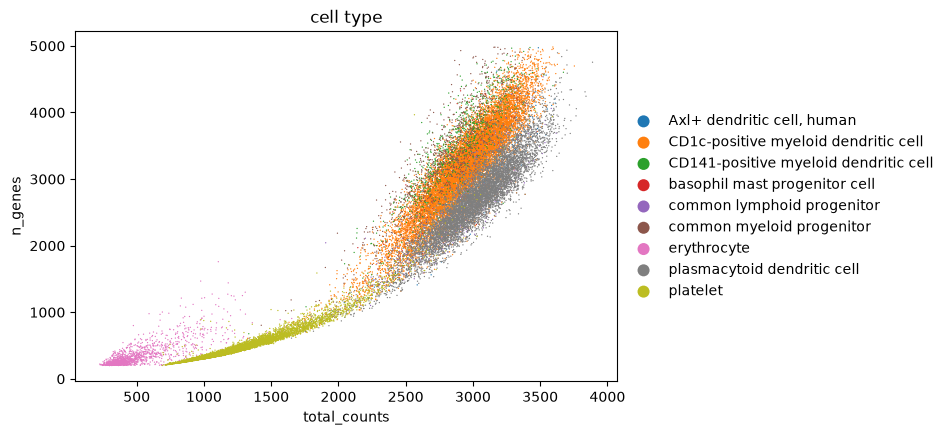

In [8]:
import scanpy as sc

sc.pl.scatter(allen, x="total_counts", y="n_genes", color="cell_type", show=True)

## What just happened

| Step | Cost |
|---|---|
| Referenced two atlases (10 GB) into one repo | seconds; **no matrix copied** |
| Opened either study as `AnnData` | instant — nothing loaded |
| Explored 850k cells of metadata + embeddings | free — lives in the repo |
| `n_genes` for every cell | free — from `indptr`, no matrix read |
| `total_counts` for the cells we chose | seconds — only their byte ranges |
| Stored the metrics back | native chunks in the same repo |

After `open_anndata`, there is no `virtual_h5ad` API in sight — just `AnnData` and
`scanpy`. The repo is a thin, self-contained index over the original files that
you can also **write new results into**.